<a href="https://colab.research.google.com/github/summerof69/marketing-channel-attribution/blob/main/notebooks/attribution_3_lndc_problem_why_multi_touch_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Marketing Channel Attribution, Part 3: the last-click trap

- Python notebook for **Part 3** of the series.
- It compares last click (LC) with last non-direct click (LNDC), shows how much credit TOF and BOF channels get under each model, computes TaskHarbor's attributed ROAS, and regenerates every figure in Part 3.
- All companies and numbers are fictional and seeded, so every run reproduces the blog exactly.

## 1.Channels, journey generator and attribution models

- Every report uses the two funnel stages
- **TOF** (top of funnel) is every touch up to the moment of intent, which is add to cart at Kesari Threads and the demo request at TaskHarbor
- **BOF** (bottom of funnel) is everything after it. The generator also gives each channel a journey role (opener, nurture or closer). That role only decides where a channel tends to appear in a simulated journey; it is never used in a report.
- TaskHarbor is simulated in USD and converted to INR at a fixed ₹80 per USD, so every amount in the series is in rupees. Each model takes one ordered journey and returns credit weights that add up to 1.

In [ ]:
from __future__ import annotations

from collections import defaultdict

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Channel definitions
# ---------------------------------------------------------------------------
# Funnel stage used in every report, as defined in Part 1 of the series:
#   TOF (top of funnel)    = touches up to the moment of intent
#                            (add to cart at Kesari, the demo request at TaskHarbor)
#   BOF (bottom of funnel) = touches after it

D2C_CHANNELS = {
    "Instagram Ads":   "TOF",
    "YouTube":         "TOF",
    "Influencer":      "TOF",
    "Google Shopping": "TOF",
    "Email":           "BOF",   # grouped with BOF, following Part 1's cart-reminder example
    "Brand Search":    "BOF",
    "Direct":          "BOF",
}

B2B_CHANNELS = {
    "LinkedIn Ads":    "TOF",
    "Content / SEO":   "TOF",
    "Webinar":         "TOF",
    "Review Sites":    "TOF",
    "Email Nurture":   "TOF",   # nurture emails go to leads before the demo request
    "Brand Search":    "BOF",
    "Direct":          "BOF",
}

# Journey role, used only by the generator to place channels realistically:
# openers tend to start a journey, closers tend to end it, nurture sits between.
D2C_ROLES = {
    "Instagram Ads": "opener", "YouTube": "opener", "Influencer": "opener",
    "Google Shopping": "nurture", "Email": "nurture",
    "Brand Search": "closer", "Direct": "closer",
}
B2B_ROLES = {
    "LinkedIn Ads": "opener", "Content / SEO": "opener",
    "Webinar": "nurture", "Review Sites": "nurture", "Email Nurture": "nurture",
    "Brand Search": "closer", "Direct": "closer",
}

USD_TO_INR = 80  # TaskHarbor is simulated in USD, then reported in INR at a fixed rate

# Media / programme spend per channel for the period the journeys cover (illustrative).
# Direct has no spend. Brand Search is cheap because people already know you.
D2C_SPEND_INR = {
    "Instagram Ads": 900_000, "YouTube": 600_000, "Influencer": 500_000,
    "Google Shopping": 700_000, "Email": 100_000, "Brand Search": 200_000,
    "Direct": 0,
}
B2B_SPEND_INR = {  # annual programme spend for the same period as the 600 deals
    ch: usd * USD_TO_INR for ch, usd in {
        "LinkedIn Ads": 900_000, "Content / SEO": 400_000, "Webinar": 300_000,
        "Review Sites": 200_000, "Email Nurture": 80_000, "Brand Search": 150_000,
        "Direct": 0,
    }.items()
}


# ---------------------------------------------------------------------------
# 2. Journey generator
# ---------------------------------------------------------------------------
def _pick(rng, roles: dict, role: str, weights: dict | None = None) -> str:
    names = [c for c, r in roles.items() if r == role]
    p = np.array([weights.get(c, 1.0) if weights else 1.0 for c in names])
    return rng.choice(names, p=p / p.sum())


def generate_journeys(
    business: str = "d2c", n: int = 2000, seed: int = 42
) -> pd.DataFrame:
    """Return one row per touchpoint of converting journeys.

    Columns: journey_id, step, channel, stage, days_before_conversion, revenue
    Journeys follow a realistic shape: they usually *start* with opener
    channels (social, video, LinkedIn), pass through nurture channels and *end*
    on closers such as Brand Search or Direct. The `stage` column holds the
    TOF/BOF reporting stage. Revenue is INR for both companies.
    """
    rng = np.random.default_rng(seed)
    if business == "d2c":
        channels, roles = D2C_CHANNELS, D2C_ROLES
        mean_extra_touches, max_days = 2.0, 21
        tof_w = {"Instagram Ads": 3, "YouTube": 1.5, "Influencer": 1.5}
        mof_w = {"Google Shopping": 2, "Email": 1.5}
        bof_w = {"Brand Search": 1.3, "Direct": 1.0}
    elif business == "b2b":
        channels, roles = B2B_CHANNELS, B2B_ROLES
        mean_extra_touches, max_days = 6.0, 120
        tof_w = {"LinkedIn Ads": 2.5, "Content / SEO": 1.5}
        mof_w = {"Webinar": 1.2, "Review Sites": 1.0, "Email Nurture": 2.0}
        bof_w = {"Brand Search": 1.2, "Direct": 1.0}
    else:
        raise ValueError("business must be 'd2c' or 'b2b'")

    rows = []
    for j in range(n):
        n_touch = 1 + rng.poisson(mean_extra_touches)
        path = []
        for k in range(n_touch):
            pos = k / max(n_touch - 1, 1)  # 0 = first touch, 1 = last touch
            if n_touch == 1:
                stage_p = [0.25, 0.25, 0.50]  # single-touch: mostly intent
            elif k == 0:
                stage_p = [0.75, 0.20, 0.05]
            elif k == n_touch - 1:
                stage_p = [0.05, 0.20, 0.75]
            else:
                stage_p = [0.45 * (1 - pos) + 0.10,
                           0.55,
                           0.45 * pos - 0.10 + 0.0]
                stage_p = np.clip(stage_p, 0.02, None)
                stage_p = stage_p / stage_p.sum()
            role = rng.choice(["opener", "nurture", "closer"], p=stage_p)
            w = {"opener": tof_w, "nurture": mof_w, "closer": bof_w}[role]
            path.append(_pick(rng, roles, role, w))

        # days before conversion: first touch is oldest, last touch is day 0
        span = rng.uniform(0.2, 1.0) * max_days
        days = np.sort(rng.uniform(0, span, n_touch))[::-1]
        days[-1] = 0.0

        if business == "d2c":  # order value in INR
            revenue = float(np.round(rng.lognormal(np.log(2400), 0.45), -1))
        else:                  # first-year ARR, simulated in USD and reported in INR
            revenue = float(np.round(rng.lognormal(np.log(9000), 0.6), -2)) * USD_TO_INR

        for k, ch in enumerate(path):
            rows.append({
                "journey_id": f"{business.upper()}-{j:05d}",
                "step": k + 1,
                "channel": ch,
                "stage": channels[ch],
                "days_before_conversion": round(float(days[k]), 1),
                "revenue": revenue,
            })
    return pd.DataFrame(rows)


# ---------------------------------------------------------------------------
# 3. Attribution models
# ---------------------------------------------------------------------------
# Every model takes one journey (an ordered list of channels, plus optional
# days-before-conversion) and returns {channel: weight}, weights summing to 1.

def first_touch(path, days=None):
    return {path[0]: 1.0}


def last_click(path, days=None):
    """Last click (LC), also called last touch: the final touchpoint gets everything."""
    return {path[-1]: 1.0}


def last_non_direct(path, days=None, direct="Direct"):
    """Last Non-Direct Click: like last click (LC), but skips Direct visits.
    If the whole journey is Direct, Direct keeps the credit."""
    non_direct = [c for c in path if c != direct]
    return {(non_direct[-1] if non_direct else direct): 1.0}


def linear(path, days=None):
    w = defaultdict(float)
    for c in path:
        w[c] += 1.0 / len(path)
    return dict(w)


def position_based(path, days=None, first=0.4, last=0.4):
    """U-shaped: 40% first touch, 40% last touch, 20% spread over the middle."""
    n = len(path)
    if n == 1:
        return {path[0]: 1.0}
    if n == 2:
        w = defaultdict(float)
        w[path[0]] += 0.5
        w[path[1]] += 0.5
        return dict(w)
    w = defaultdict(float)
    w[path[0]] += first
    w[path[-1]] += last
    middle = (1 - first - last) / (n - 2)
    for c in path[1:-1]:
        w[c] += middle
    return dict(w)


def time_decay(path, days, half_life=7.0):
    """Touches closer to conversion get more credit: weight = 2^(-days/half_life)."""
    raw = np.power(2.0, -np.asarray(days, dtype=float) / half_life)
    raw = raw / raw.sum()
    w = defaultdict(float)
    for c, r in zip(path, raw):
        w[c] += float(r)
    return dict(w)


MODELS = {
    "First touch": first_touch,
    "Last click (LC)": last_click,
    "Last non-direct": last_non_direct,
    "Linear": linear,
    "Position-based": position_based,
    "Time decay": time_decay,
}


def attribute(df: pd.DataFrame, model, value: str = "revenue") -> pd.Series:
    """Apply one model to every journey. Returns attributed value by channel.
    value='revenue' distributes money; value='conversions' distributes counts."""
    credit = defaultdict(float)
    for _, g in df.sort_values(["journey_id", "step"]).groupby("journey_id"):
        path = g["channel"].tolist()
        days = g["days_before_conversion"].tolist()
        amount = 1.0 if value == "conversions" else g["revenue"].iloc[0]
        for ch, w in model(path, days).items():
            credit[ch] += w * amount
    return pd.Series(credit)


def compare_models(df: pd.DataFrame, value: str = "revenue") -> pd.DataFrame:
    """Attributed value by channel (rows) for every model (columns)."""
    out = pd.DataFrame({name: attribute(df, fn, value) for name, fn in MODELS.items()})
    return out.fillna(0.0)


def share_table(table: pd.DataFrame) -> pd.DataFrame:
    return (table / table.sum() * 100).round(1)


def stage_share(table: pd.DataFrame, channels: dict) -> pd.DataFrame:
    """Share of credit going to TOF and BOF channels under each model."""
    st = table.groupby(table.index.map(channels)).sum()
    return (st / st.sum() * 100).round(1).reindex(["TOF", "BOF"])


def roas_table(table: pd.DataFrame, spend: dict) -> pd.DataFrame:
    """Attributed revenue / spend for each paid channel under each model."""
    s = pd.Series(spend)
    s = s[s > 0]
    return table.loc[s.index].div(s, axis=0).round(2)


def zero_credit_share(df: pd.DataFrame) -> float:
    """% of all touchpoints that get no credit under a single-touch model (LC or LNDC)."""
    return round(float((1 - df["journey_id"].nunique() / len(df)) * 100), 1)


def journey_summary(df: pd.DataFrame) -> dict:
    lengths = df.groupby("journey_id")["step"].max()
    return {
        "journeys": int(lengths.size),
        "mean_touches": round(float(lengths.mean()), 1),
        "median_touches": float(lengths.median()),
        "single_touch_pct": round(float((lengths == 1).mean() * 100), 1),
        "zero_credit_touch_pct_lc": zero_credit_share(df),
        "revenue_total": float(df.groupby("journey_id")["revenue"].first().sum()),
    }


# ---------------------------------------------------------------------------
# 4. A worked single journey (used in Part 2)
# ---------------------------------------------------------------------------
EXAMPLE_PATH = ["Instagram Ads", "Email", "Google Shopping", "Direct"]
EXAMPLE_DAYS = [14, 6, 2, 0]
EXAMPLE_REVENUE = 3000  # INR


def example_journey_split() -> pd.DataFrame:
    rows = {}
    for name, fn in MODELS.items():
        rows[name] = {ch: w * EXAMPLE_REVENUE for ch, w in fn(EXAMPLE_PATH, EXAMPLE_DAYS).items()}
    return pd.DataFrame(rows).T.reindex(columns=EXAMPLE_PATH).fillna(0).round(0)

## 2.Generate the dummy data and save it as CSV

One row per touchpoint of a converting journey.
| Column | Description |
| --- | --- |
| `journey_id` | ID of one customer's path to a single conversion. `D2C-xxxxx` = Kesari Threads order, `B2B-xxxxx` = TaskHarbor deal. All rows with the same ID belong to one journey. |
| `step` | Order of the touchpoint in its journey. `1` = first touch; the highest step = last touch. |
| `channel` | The source the touchpoint came from, e.g. Instagram Ads, Email, Google Shopping, Brand Search, Direct. |
| `stage` | `TOF` = up to add to cart (Kesari) or the demo request (TaskHarbor); `BOF` = after it. |
| `days_before_conversion` | Days before the conversion the touch happened. The last touch is always `0`. |
| `revenue` | Conversion value in INR (Kesari order value, or TaskHarbor first-year ARR at ₹80/USD). Repeats on every row of a journey, so take one value per `journey_id` before summing. |
| `company` | `Kesari Threads` (fictional D2C brand) or `TaskHarbor` (fictional B2B SaaS). |

In [ ]:
d2c = generate_journeys("d2c", n=2000, seed=42)
b2b = generate_journeys("b2b", n=600, seed=7)
data = pd.concat([d2c.assign(company="Kesari Threads"), b2b.assign(company="TaskHarbor")])
data.to_csv("attribution-3-lndc-problem-why-multi-touch-data.csv", index=False)
data.head(8)

,journey_id,step,channel,stage,days_before_conversion,revenue,company
0,D2C-00000,1,Direct,BOF,6.6,1770.0,Kesari Threads
1,D2C-00000,2,Google Shopping,TOF,6.1,1770.0,Kesari Threads
2,D2C-00000,3,Google Shopping,TOF,5.1,1770.0,Kesari Threads
3,D2C-00000,4,Direct,BOF,4.4,1770.0,Kesari Threads
4,D2C-00000,5,Brand Search,BOF,0.0,1770.0,Kesari Threads
5,D2C-00001,1,Instagram Ads,TOF,5.8,3220.0,Kesari Threads
6,D2C-00001,2,YouTube,TOF,2.7,3220.0,Kesari Threads
7,D2C-00001,3,Email,BOF,2.3,3220.0,Kesari Threads


### 2.1Journey summary for both companies


One column per company. Each row answers a simple question about its journeys:

| Row | What it tells you |
| --- | --- |
| `journeys` | How many conversions there are: 2,000 Kesari orders and 600 TaskHarbor deals. |
| `mean_touches` | The average number of touchpoints before a conversion. |
| `median_touches` | The typical number of touchpoints: half of all journeys have fewer, half have more. |
| `single_touch_pct` | The % of journeys with only one touchpoint. Every attribution model gives the same answer for these. |
| `zero_credit_touch_pct_lc` | The % of all touchpoints that get **no credit at all** under last click (LC) or LNDC. Those models give 100% of the credit to one touchpoint per journey, so every other touchpoint gets nothing. For example, Kesari has 6,018 touchpoints but only 2,000 orders, so only 2,000 touchpoints get any credit and 4,018 (66.8%) get none. |
| `revenue_total` | Total revenue across all journeys, in INR. |


In [ ]:
pd.DataFrame({'Kesari Threads': journey_summary(d2c), 'TaskHarbor': journey_summary(b2b)})

,Kesari Threads,TaskHarbor
journeys,2000.0,600.0
mean_touches,3.0,7.1
median_touches,3.0,7.0
single_touch_pct,13.6,0.2
zero_credit_touch_pct_lc,66.8,85.9
revenue_total,5338320.0,522584000.0


## 3.Plot settings

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.patches import FancyBboxPatch

OUT = "."  # figures are saved next to the notebook
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "font.size": 12,
    "axes.titlesize": 15, "axes.titleweight": "bold", "axes.labelsize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
})
STAGE_COL = {"TOF": "#3b82f6", "BOF": "#ef4444"}
TOUCH_COL = ["#3b82f6", "#a855f7", "#f59e0b", "#ef4444"]  # Instagram, Email, Google Shopping, Direct
LC = "Last click (LC)"
MODEL_ORDER = list(MODELS.keys())
FUNNEL_ORDER = ["Influencer", "Instagram Ads", "YouTube", "Google Shopping", "Email",
                "LinkedIn Ads", "Content / SEO", "Review Sites", "Webinar", "Email Nurture",
                "Brand Search", "Direct"]
rev_d2c = compare_models(d2c, "revenue")
rev_b2b = compare_models(b2b, "revenue")


def save(fig, name):
    """Save the figure next to the notebook and show it."""
    fig.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)

In [ ]:
PANELS = [(rev_d2c, D2C_CHANNELS, "Kesari Threads (D2C)"), (rev_b2b, B2B_CHANNELS, "TaskHarbor (B2B SaaS)")]

## 4.1Figure 1: LC vs LNDC

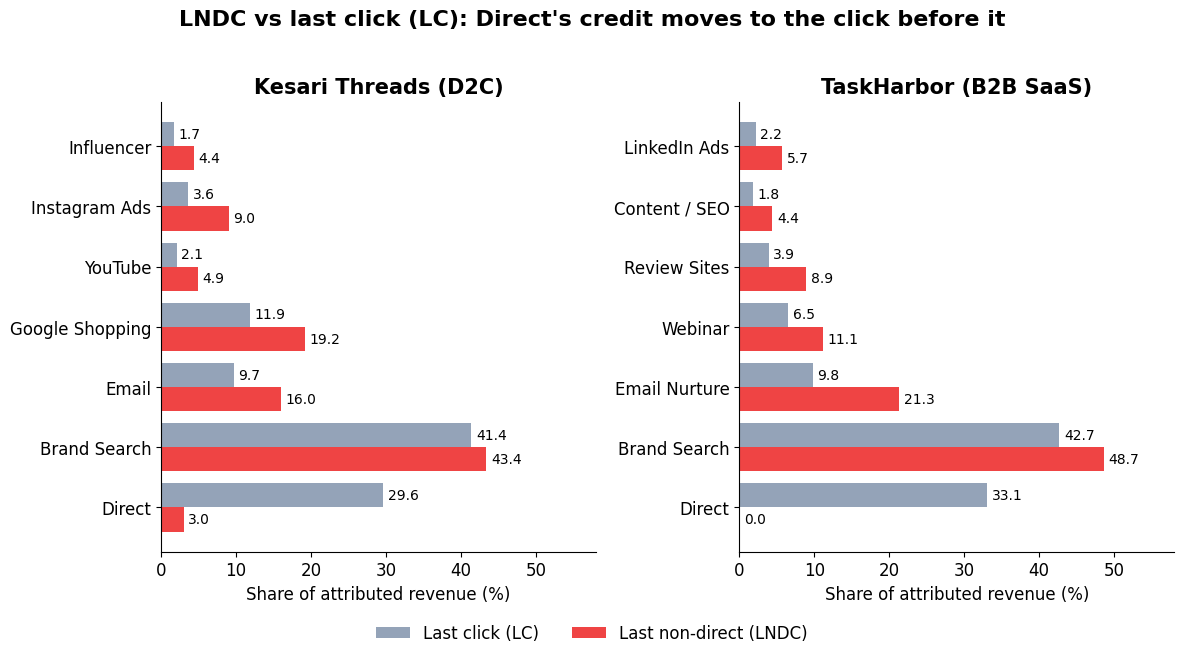

In [ ]:
def fig_lc_vs_lndc():
    """Part 3, Figure 1: LC vs LNDC share by channel for both companies."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    for ax, (rev, chs, name) in zip(axes, PANELS):
        sh = share_table(rev)[[LC, "Last non-direct"]]
        sh = sh.loc[sorted(sh.index, key=FUNNEL_ORDER.index)]
        y = np.arange(len(sh))
        ax.barh(y - 0.2, sh[LC], height=0.4, color="#94a3b8", label=LC)
        ax.barh(y + 0.2, sh["Last non-direct"], height=0.4, color="#ef4444", label="Last non-direct (LNDC)")
        for yi, (a, b) in enumerate(zip(sh[LC], sh["Last non-direct"])):
            ax.text(a + 0.6, yi - 0.2, f"{a:.1f}", va="center", fontsize=10)
            ax.text(b + 0.6, yi + 0.2, f"{b:.1f}", va="center", fontsize=10)
        ax.set_yticks(y, sh.index); ax.invert_yaxis()
        ax.set_xlabel("Share of attributed revenue (%)")
        ax.set_title(name); ax.set_xlim(0, 58)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.06))
    fig.suptitle("LNDC vs last click (LC): Direct's credit moves to the click before it", fontsize=16, weight="bold", y=1.02)
    fig.tight_layout()
    save(fig, "03-lc-vs-lndc.png")


fig_lc_vs_lndc()

## 4.2Figure 2: credit by funnel stage (TOF and BOF)

In [ ]:
pd.concat({'Kesari Threads': stage_share(rev_d2c, D2C_CHANNELS)[MODEL_ORDER],
           'TaskHarbor': stage_share(rev_b2b, B2B_CHANNELS)[MODEL_ORDER]})

First touch  Last click (LC)  Last non-direct  Linear  \
Kesari Threads TOF         78.4             19.3             37.5    52.6   
               BOF         21.6             80.7             62.5    47.4   
TaskHarbor     TOF         94.2             24.2             51.3    77.1   
               BOF          5.8             75.8             48.7    22.9   

                    Position-based  Time decay  
Kesari Threads TOF            50.5        43.1  
               BOF            49.5        56.9  
TaskHarbor     TOF            64.4        41.5  
               BOF            35.6        58.5

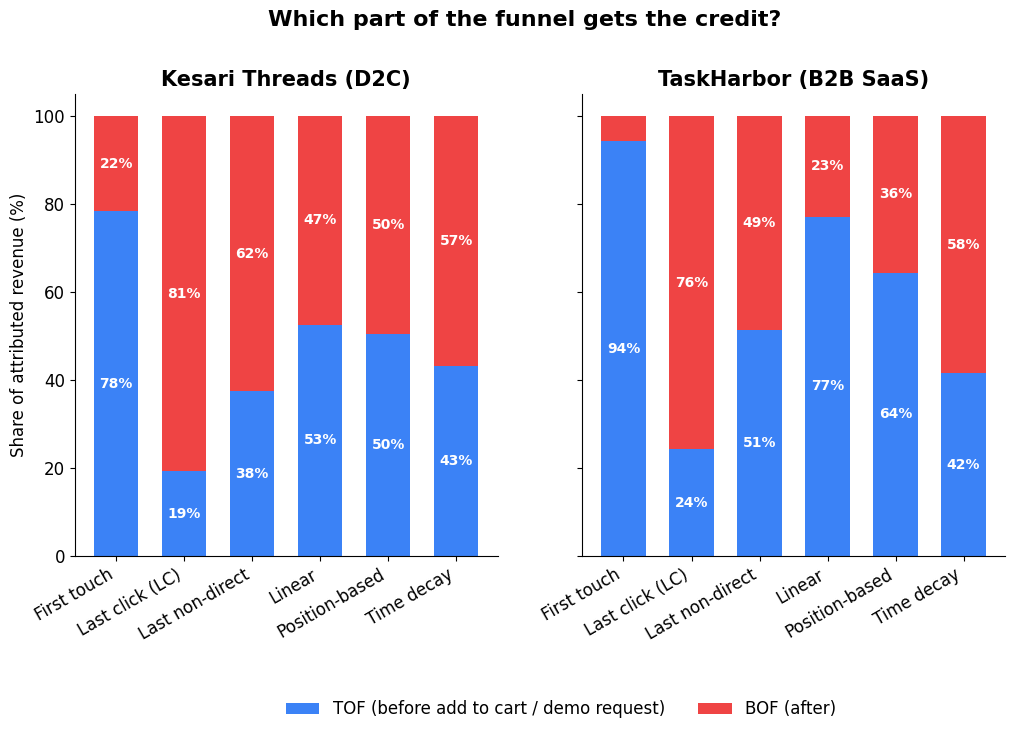

In [ ]:
def fig_stage_credit():
    """Part 3, Figure 2: share of revenue to TOF and BOF channels under each model."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
    for ax, (rev, chs, name) in zip(axes, PANELS):
        st = stage_share(rev, chs)[MODEL_ORDER]
        bottom = np.zeros(len(MODEL_ORDER))
        for s, lab in [("TOF", "TOF (before add to cart / demo request)"), ("BOF", "BOF (after)")]:
            ax.bar(MODEL_ORDER, st.loc[s], bottom=bottom, color=STAGE_COL[s], label=lab, width=0.65)
            for i, (v, b) in enumerate(zip(st.loc[s], bottom)):
                if v >= 6:
                    ax.text(i, b + v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=10, weight="bold")
            bottom += st.loc[s].values
        ax.set_title(name)
        ax.tick_params(axis="x", rotation=30)
        for lab in ax.get_xticklabels():
            lab.set_ha("right")
    axes[0].set_ylabel("Share of attributed revenue (%)")
    axes[1].legend(loc="upper center", bbox_to_anchor=(-0.05, -0.28), ncol=2, frameon=False)
    fig.suptitle("Which part of the funnel gets the credit?", fontsize=16, weight="bold", y=1.02)
    save(fig, "03-funnel-stage-credit-tof-bof.png")


fig_stage_credit()

## 4.3Figure 3: TaskHarbor ROAS by model

In [ ]:
roas_table(rev_b2b, B2B_SPEND_INR)

,First touch,Last click (LC),Last non-direct,Linear,Position-based,Time decay
LinkedIn Ads,3.00,0.16,0.41,1.46,1.54,0.47
Content / SEO,5.18,0.30,0.72,2.30,2.61,0.72
Webinar,1.08,1.42,2.41,2.76,1.69,2.04
Review Sites,1.81,1.26,2.89,3.29,2.05,2.25
Email Nurture,8.74,8.03,17.36,16.45,10.82,11.69
Brand Search,1.41,18.60,21.20,5.44,8.66,14.39


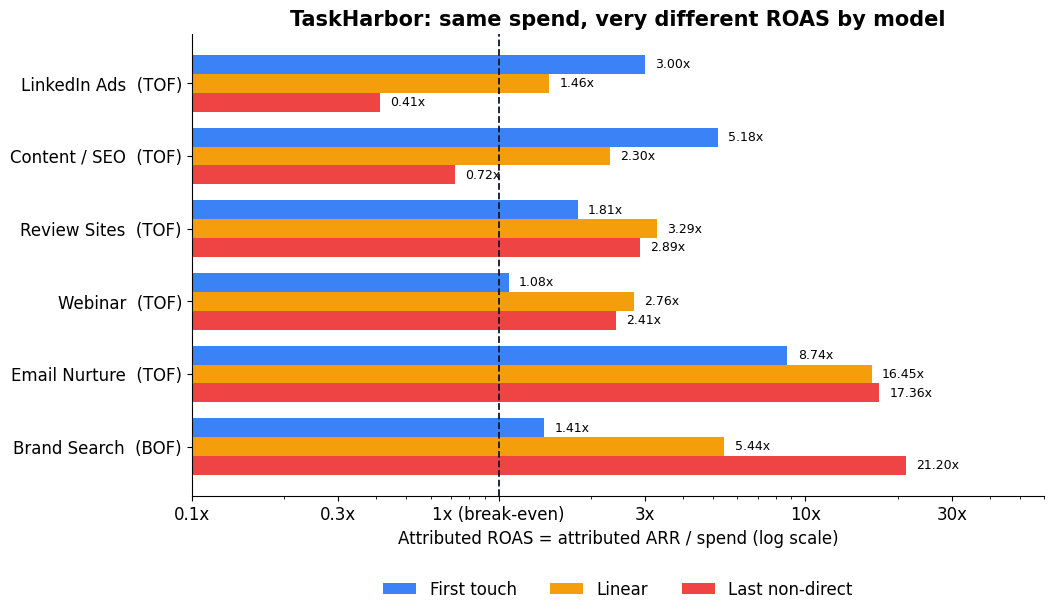

In [ ]:
def fig_roas():
    """Part 3, Figure 3: TaskHarbor attributed ROAS under three models (log scale)."""
    r = roas_table(rev_b2b, B2B_SPEND_INR)[["First touch", "Linear", "Last non-direct"]]
    r = r.loc[sorted(r.index, key=FUNNEL_ORDER.index)]
    fig, ax = plt.subplots(figsize=(11, 6))
    y = np.arange(len(r))
    for k, (m, col) in enumerate([("First touch", "#3b82f6"), ("Linear", "#f59e0b"), ("Last non-direct", "#ef4444")]):
        ax.barh(y + (k - 1) * 0.26, r[m], height=0.26, color=col, label=m)
        for yi, v in enumerate(r[m]):
            ax.text(v * 1.08, yi + (k - 1) * 0.26, f"{v:.2f}x", va="center", fontsize=9)
    ax.axvline(1, color="#0f172a", ls="--", lw=1.3)
    ax.set_xscale("log"); ax.set_xlim(0.1, 60)
    ax.set_xticks([0.1, 0.3, 1, 3, 10, 30], ["0.1x", "0.3x", "1x (break-even)", "3x", "10x", "30x"])
    ax.set_yticks(y, [f"{c}  ({B2B_CHANNELS[c]})" for c in r.index]); ax.invert_yaxis()
    ax.set_xlabel("Attributed ROAS = attributed ARR / spend (log scale)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    ax.set_title("TaskHarbor: same spend, very different ROAS by model")
    save(fig, "03-taskharbor-roas-by-model.png")


fig_roas()

### The ROAS check from the article

Attributed ARR divided by spend, both in INR. (The article's code block rounds the ARR values; the ratios are the same.)

In [ ]:
attributed = rev_b2b.loc[['LinkedIn Ads', 'Brand Search'], ['First touch', 'Last non-direct']]
spend = pd.Series(B2B_SPEND_INR)[attributed.index]
display(attributed)
attributed.div(spend, axis=0).round(2)

,First touch,Last non-direct
LinkedIn Ads,215672000.0,29840000.0
Brand Search,16888000.0,254392000.0


,First touch,Last non-direct
LinkedIn Ads,3.00,0.41
Brand Search,1.41,21.20


## 4.4Figure 4: the LNDC doom loop

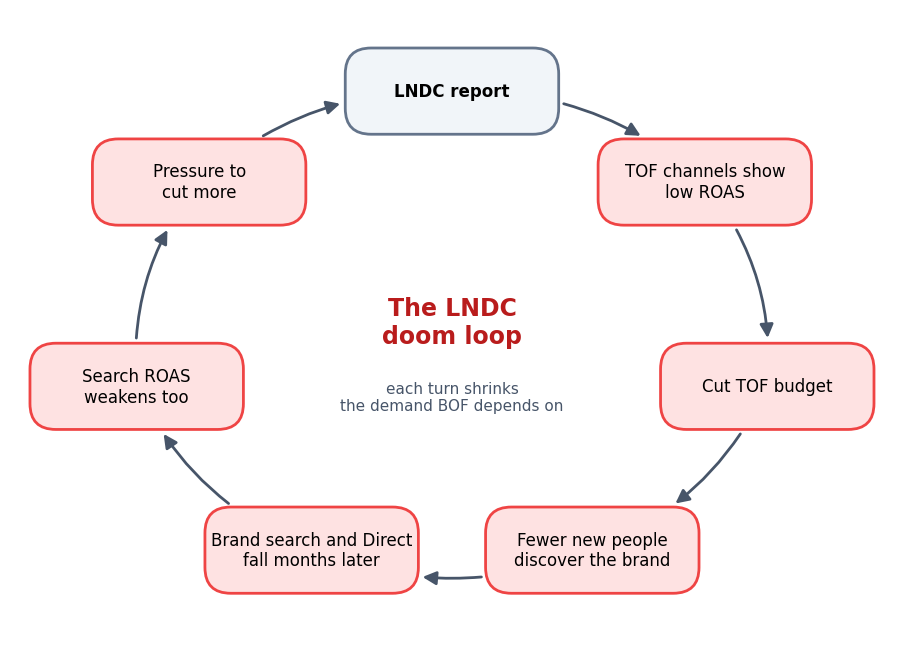

In [ ]:
def draw_boxes(ax, nodes, w, h, styles, fontsize=13):
    """Rounded boxes keyed by name: nodes = {key: (x, y, text, style)}. Returns the patches."""
    patches = {}
    for key, (x, y, text, kind) in nodes.items():
        fill, edge, bold = styles[kind]
        p = FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                           facecolor=fill, edgecolor=edge, linewidth=2, zorder=3)
        ax.add_patch(p)
        ax.text(x, y, text, ha="center", va="center", fontsize=fontsize, zorder=4,
                fontweight="bold" if bold else "normal")
        patches[key] = p
    return patches


def fig_doom_loop():
    """Part 3, Figure 4: how budgets set on LNDC can feed on themselves."""
    steps = ["LNDC report", "TOF channels show\nlow ROAS", "Cut TOF budget", "Fewer new people\ndiscover the brand",
             "Brand search and Direct\nfall months later", "Search ROAS\nweakens too", "Pressure to\ncut more"]
    fig, ax = plt.subplots(figsize=(11.5, 8.4))
    ax.set_xlim(-2.05, 2.05); ax.set_ylim(-1.5, 1.5); ax.set_aspect("equal"); ax.axis("off")
    ang = [np.pi / 2 - 2 * np.pi * i / len(steps) for i in range(len(steps))]
    nodes = {i: (1.5 * np.cos(a), 1.12 * np.sin(a), s, "start" if i == 0 else "step")
             for i, (a, s) in enumerate(zip(ang, steps))}
    styles = {"start": ("#f1f5f9", "#64748b", True), "step": ("#fee2e2", "#ef4444", False)}
    boxes = draw_boxes(ax, nodes, 0.95, 0.36, styles, fontsize=12)
    for i in nodes:
        j = (i + 1) % len(nodes)
        ax.annotate("", xy=nodes[j][:2], xytext=nodes[i][:2], zorder=5,
                    arrowprops=dict(arrowstyle="-|>", color="#475569", lw=2, mutation_scale=20,
                                    connectionstyle="arc3,rad=-0.2", patchA=boxes[i], patchB=boxes[j],
                                    shrinkA=3, shrinkB=3))
    ax.text(0, 0.05, "The LNDC\ndoom loop", ha="center", va="center", fontsize=17, weight="bold", color="#b91c1c")
    ax.text(0, -0.3, "each turn shrinks\nthe demand BOF depends on", ha="center", va="center", fontsize=11, color="#475569")
    save(fig, "03-lndc-doom-loop.png")


fig_doom_loop()

## How much of the journey LC and LNDC ignore

Under a single-touch model, only one touch per journey gets credit. The share of all touchpoints left with nothing:

In [ ]:
pd.Series({'Kesari Threads': zero_credit_share(d2c), 'TaskHarbor': zero_credit_share(b2b)}, name='% of touches with zero credit')

,% of touches with zero credit
Kesari Threads,66.8
TaskHarbor,85.9
